# Best model: reproduce and extend

Three arms, each the strongest method from one notebook. All arms are scored on the same CV splits, and every combination of them is compared.

| arm | from | idea |
|---|---|---|
| **centroid** | `analysis.ipynb` | cosine centroid on calibrated profiles, soft pathway-superclass labels, PARP (p53) and RAF (ERK paradox) evidence terms |
| **lightgbm** | `analysis.ipynb` | LightGBM on single signatures, averaged per compound |
| **reverse** | `pathway_graph_models.ipynb` | class dose-response templates (amplitude + potency shift) on the co-expression-graph high-pass residual |

**CV**: grouped by compound, stratified 4-fold, seeds 2-11 (as in `analysis.ipynb`), plus seeds 12-21 held out from every choice made here.
**Decision rule**: score / prior^alpha, with alpha chosen inside each training fold (nested).

In [1]:
import warnings, numpy as np, pandas as pd, lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

DATA = ".."                                   # folder with X_train.csv.gz etc.
CTRL = "BRD-K60230970"                        # 300-replicate plate control: dropped from training
DOSES = [0.04, 0.12, 0.37, 1.11, 3.33, 10.0]
SEEDS, FRESH = list(range(2, 12)), list(range(12, 22))

## Data
Genes are calibrated by the median and MAD of the unlabelled compounds. A compound profile is the mean of its 3.33 and 10 µM signatures.

In [2]:
rd = lambda f: pd.read_csv(f"{DATA}/{f}")
X_un = rd("X_unlabeled.csv.gz")
CLASSES = [l.strip() for l in open(f"{DATA}/classes.txt") if l.strip()]; K = len(CLASSES)
GENES = [c for c in X_un.columns if c not in ("sample_id", "compound", "dose_um")]
sig = rd("meta_train.csv").merge(rd("y_train.csv"), on="sample_id").query("compound != @CTRL").merge(rd("X_train.csv.gz"), on="sample_id")
te_sig = rd("meta_test.csv").merge(rd("X_test.csv.gz"), on="sample_id")

prof = lambda d: d[d.dose_um.isin([3.33, 10.0])].groupby("compound")[GENES].mean()
P_un = prof(X_un[X_un.compound != CTRL])
MED = P_un.median().values; MAD = (P_un - MED).abs().median().values * 1.4826; MAD[MAD < 1e-6] = 1
cal = lambda V: (V - MED) / MAD

comps, test_comps = prof(sig).index.values, prof(te_sig).index.values
allc = np.r_[comps, test_comps]; n = len(comps)              # bank: training compounds first, then test
both = pd.concat([sig, te_sig])
Z = cal(np.vstack([prof(sig).values, prof(te_sig).values]))  # compound profiles
Zs = cal(both[GENES].values)                                 # signatures
sc = pd.Index(allc).get_indexer(both.compound)               # bank index of every signature
y = sig.groupby("compound").moa.first().reindex(comps).values
yi = np.array([CLASSES.index(c) for c in y])
print(f"{n} training compounds, {len(test_comps)} test compounds, {len(Zs)} signatures, {len(GENES)} genes")

86 training compounds, 29 test compounds, 689 signatures, 978 genes


## Features
**RAF**: ERK-output score per dose. The index needs a peak above control at a low dose and a fall at 10 µM (paradoxical activation).
**PARP**: p53-module score plus log amplitude.
**Graph**: kNN co-expression graph (k=10, r > 0) from the unlabelled signatures. We keep the high-pass residual X − ÂX of the raw 6-dose tensor.

In [3]:
ERK = ["208891_at", "204014_at", "201631_s_at", "206501_x_at", "204420_at", "212458_at"]   # DUSP6 DUSP4 IER3 ETV1 FOSL1 SPRED2
P53 = ["202284_s_at", "203409_at", "204781_s_at", "218346_s_at", "208478_s_at", "203725_at"]  # CDKN1A DDB2 FAS SESN1 BAX GADD45A
gi = lambda ps: [GENES.index(p) for p in ps]

erk = (pd.DataFrame({"c": sc, "d": both.dose_um.values, "v": Zs[:, gi(ERK)].mean(1)})
       .pivot_table(index="c", columns="d", values="v").T.interpolate(limit_direction="both").T)
peak = erk[DOSES[:4]].max(1)
RAF = np.minimum(peak, peak - erk[10.0]).values[:, None]
amp = pd.Series((np.abs(Zs) > 2).sum(1)).groupby(sc).max().values
PARP = np.c_[Z[:, gi(P53)].mean(1), np.log10(amp + 1)]

def tensor(c):
    """genes x 6 doses, replicates averaged; a missing dose takes the nearest measured one"""
    g = both[both.compound == c]; ld = np.log(g.dose_um.values); u = np.unique(ld)
    return np.stack([g[GENES].values[ld == u[np.abs(u - d).argmin()]].mean(0) for d in np.log(DOSES)], 1)

C = np.corrcoef(X_un[GENES].values.T); np.fill_diagonal(C, 0)
r, nn = np.arange(len(C))[:, None], np.argsort(-C, 1)[:, :10]
W = np.zeros_like(C); W[r, nn] = np.clip(C[r, nn], 0, None); W = np.maximum(W, W.T) + np.eye(len(C))
d = W.sum(1) ** -0.5
A = np.einsum("ij,njd->nid", np.eye(len(C)) - d[:, None] * W * d[None], np.stack([tensor(c) for c in allc]))

## The three arms
Each arm maps (training bank indices, query bank indices) to class probabilities.

In [4]:
SUPER = {"PI3K": "PI3K", "AKT": "PI3K", "mTOR": "PI3K", "EGFR": "MAPK", "RAF": "MAPK", "MEK": "MAPK",
         "topoisomerase": "DNA", "PARP": "DNA", "tubulin": "mitotic", "PLK": "mitotic", "proteasome": "proteo", "HSP": "proteo"}
grp = np.array([SUPER.get(c.split()[0], c) for c in CLASSES])
LGB = dict(n_estimators=456, num_leaves=5, max_depth=3, learning_rate=0.085, min_child_samples=5, subsample=0.82,
           subsample_freq=1, colsample_bytree=0.24, reg_lambda=7.69, class_weight="balanced", verbose=-1, n_jobs=4)

def softmax(L): E = np.exp(L - L.max(1, keepdims=True)); return E / E.sum(1, keepdims=True)
def unit(M): return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-9)

def centroid(tr, q, eps=0.15):
    T = np.eye(K)[yi[tr]]; sib = (grp[:, None] == grp[None]) & ~np.eye(K, dtype=bool)   # soft labels: eps of the mass to siblings
    has = sib[yi[tr]].any(1)
    T[has] = (1 - eps) * T[has] + eps * sib[yi[tr]][has] / sib[yi[tr]][has].sum(1, keepdims=True)
    P = softmax(unit(Z[q]) @ unit(T.T @ unit(Z[tr])).T / 0.1)
    for cls, w, F in [("PARP inhibitor", .1, PARP), ("RAF inhibitor", .3, RAF)]:
        lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(F[tr], y[tr] == cls)
        P[:, CLASSES.index(cls)] = (1 - w) * P[:, CLASSES.index(cls)] + w * lr.predict_proba(F[q])[:, 1]
    return P / P.sum(1, keepdims=True)

def lightgbm(tr, q):
    rt, rq = np.isin(sc, tr), np.isin(sc, q)
    m = lgb.LGBMClassifier(**LGB).fit(Zs[rt], yi[sc[rt]])
    return pd.DataFrame(m.predict_proba(Zs[rq])).groupby(sc[rq]).mean().reindex(q).values

def reverse(tr, q, shifts=(-2, -1, 0, 1, 2)):
    F = A.reshape(len(A), -1); mu, sd = F[tr].mean(0), F[tr].std(0) + 1e-6
    Ft, Fq = ((F[tr] - mu) / sd).reshape(len(tr), *A.shape[1:]), (F[q] - mu) / sd
    T = np.stack([Ft[yi[tr] == c].mean(0) for c in range(K)])
    var = np.maximum((Ft - T[yi[tr]]).reshape(len(tr), -1).var(0), 0.1)
    L = np.full((len(q), K), -np.inf)
    for c in range(K):
        for s in shifts:                                        # potency shift along the dose axis
            Ts = T[c][:, np.clip(np.arange(6) - s, 0, 5)].ravel()
            a = np.clip((Fq / var) @ Ts / (Ts ** 2 / var).sum(), 0, None)   # compound's own amplitude
            L[:, c] = np.maximum(L[:, c], -0.5 * ((Fq - a[:, None] * Ts) ** 2 / var).sum(1))
    return softmax(L / Fq.shape[1] * 20)

ARMS = {"centroid": centroid, "lightgbm": lightgbm, "reverse": reverse}

## Cross-validation
Out-of-fold probabilities for every arm, on seeds 2-21 (about 2 min).

In [5]:
def folds(seed):
    rng = np.random.default_rng(seed); f = np.empty(n, int)
    for c in np.unique(y): i = np.where(y == c)[0]; rng.shuffle(i); f[i] = np.arange(len(i)) % 4
    return f

def oof(seed):
    f = folds(seed); P = {a: np.zeros((n, K)) for a in ARMS}
    for k in range(4):
        tr, q = np.where(f != k)[0], np.where(f == k)[0]
        for a, fn in ARMS.items(): P[a][q] = fn(tr, q)
    return f, P

RUNS = {s: oof(s) for s in SEEDS + FRESH}

In [6]:
prior = np.bincount(yi, minlength=K) / n
ALPHAS = [0, .25, .5, .75, 1, 1.25]
f1 = lambda idx, P, a: f1_score(yi[idx], (P / prior ** a).argmax(1), average="macro")

def nested(P, f):
    """prior-corrected rule, alpha picked on the training folds only"""
    pred = np.empty(n, int)
    for k in range(4):
        tr, q = f != k, f == k
        a = max(ALPHAS, key=lambda a: f1(tr, P[tr], a))
        pred[q] = (P[q] / prior ** a).argmax(1)
    return pred

BLENDS = [("centroid",), ("lightgbm",), ("reverse",), ("centroid", "lightgbm"),
          ("centroid", "reverse"), ("lightgbm", "reverse"), ("centroid", "lightgbm", "reverse")]
blend = lambda P, arms: np.mean([P[a] for a in arms], 0)
PRED = {a: np.array([nested(blend(RUNS[s][1], a), RUNS[s][0]) for s in SEEDS + FRESH]) for a in BLENDS}
NS = {a: np.array([f1_score(yi, p, average="macro") for p in PRED[a]]) for a in BLENDS}
ref, sel, fr = NS[("centroid", "lightgbm")], slice(0, len(SEEDS)), slice(len(SEEDS), None)   # ref = submitted model
res = pd.DataFrame([{"model": " + ".join(a),
                     "argmax": np.mean([f1(slice(None), blend(RUNS[s][1], a), 0) for s in SEEDS]),
                     "prior-corrected": v[sel].mean(), "sd": v[sel].std(),
                     "fresh seeds": v[fr].mean(), "fresh sd": v[fr].std(),
                     "wins vs submitted (fresh)": f"{(v[fr] > ref[fr]).sum()}/{len(FRESH)}"} for a, v in NS.items()]).set_index("model")
res.round(3)

,argmax,prior-corrected,sd,fresh seeds,fresh sd,wins vs submitted (fresh)
model,,,,,,
centroid,0.689,0.681,0.019,0.681,0.026,3/10
lightgbm,0.688,0.719,0.030,0.720,0.023,8/10
reverse,0.715,0.715,0.021,0.708,0.019,4/10
centroid + lightgbm,0.699,0.728,0.014,0.715,0.014,0/10
centroid + reverse,0.701,0.698,0.017,0.688,0.017,1/10
lightgbm + reverse,0.706,0.730,0.017,0.719,0.017,5/10
centroid + lightgbm + reverse,0.700,0.737,0.014,0.725,0.016,9/10


## Where each model is right and wrong
Confusion matrices pooled over seeds 2-11, using the nested prior-corrected predictions. Rows are the true class and are normalised to recall. Diagonal cells and confusions ≥ 0.2 are labelled. Below them: per-class F1 for every model, with the hardest classes on the left.

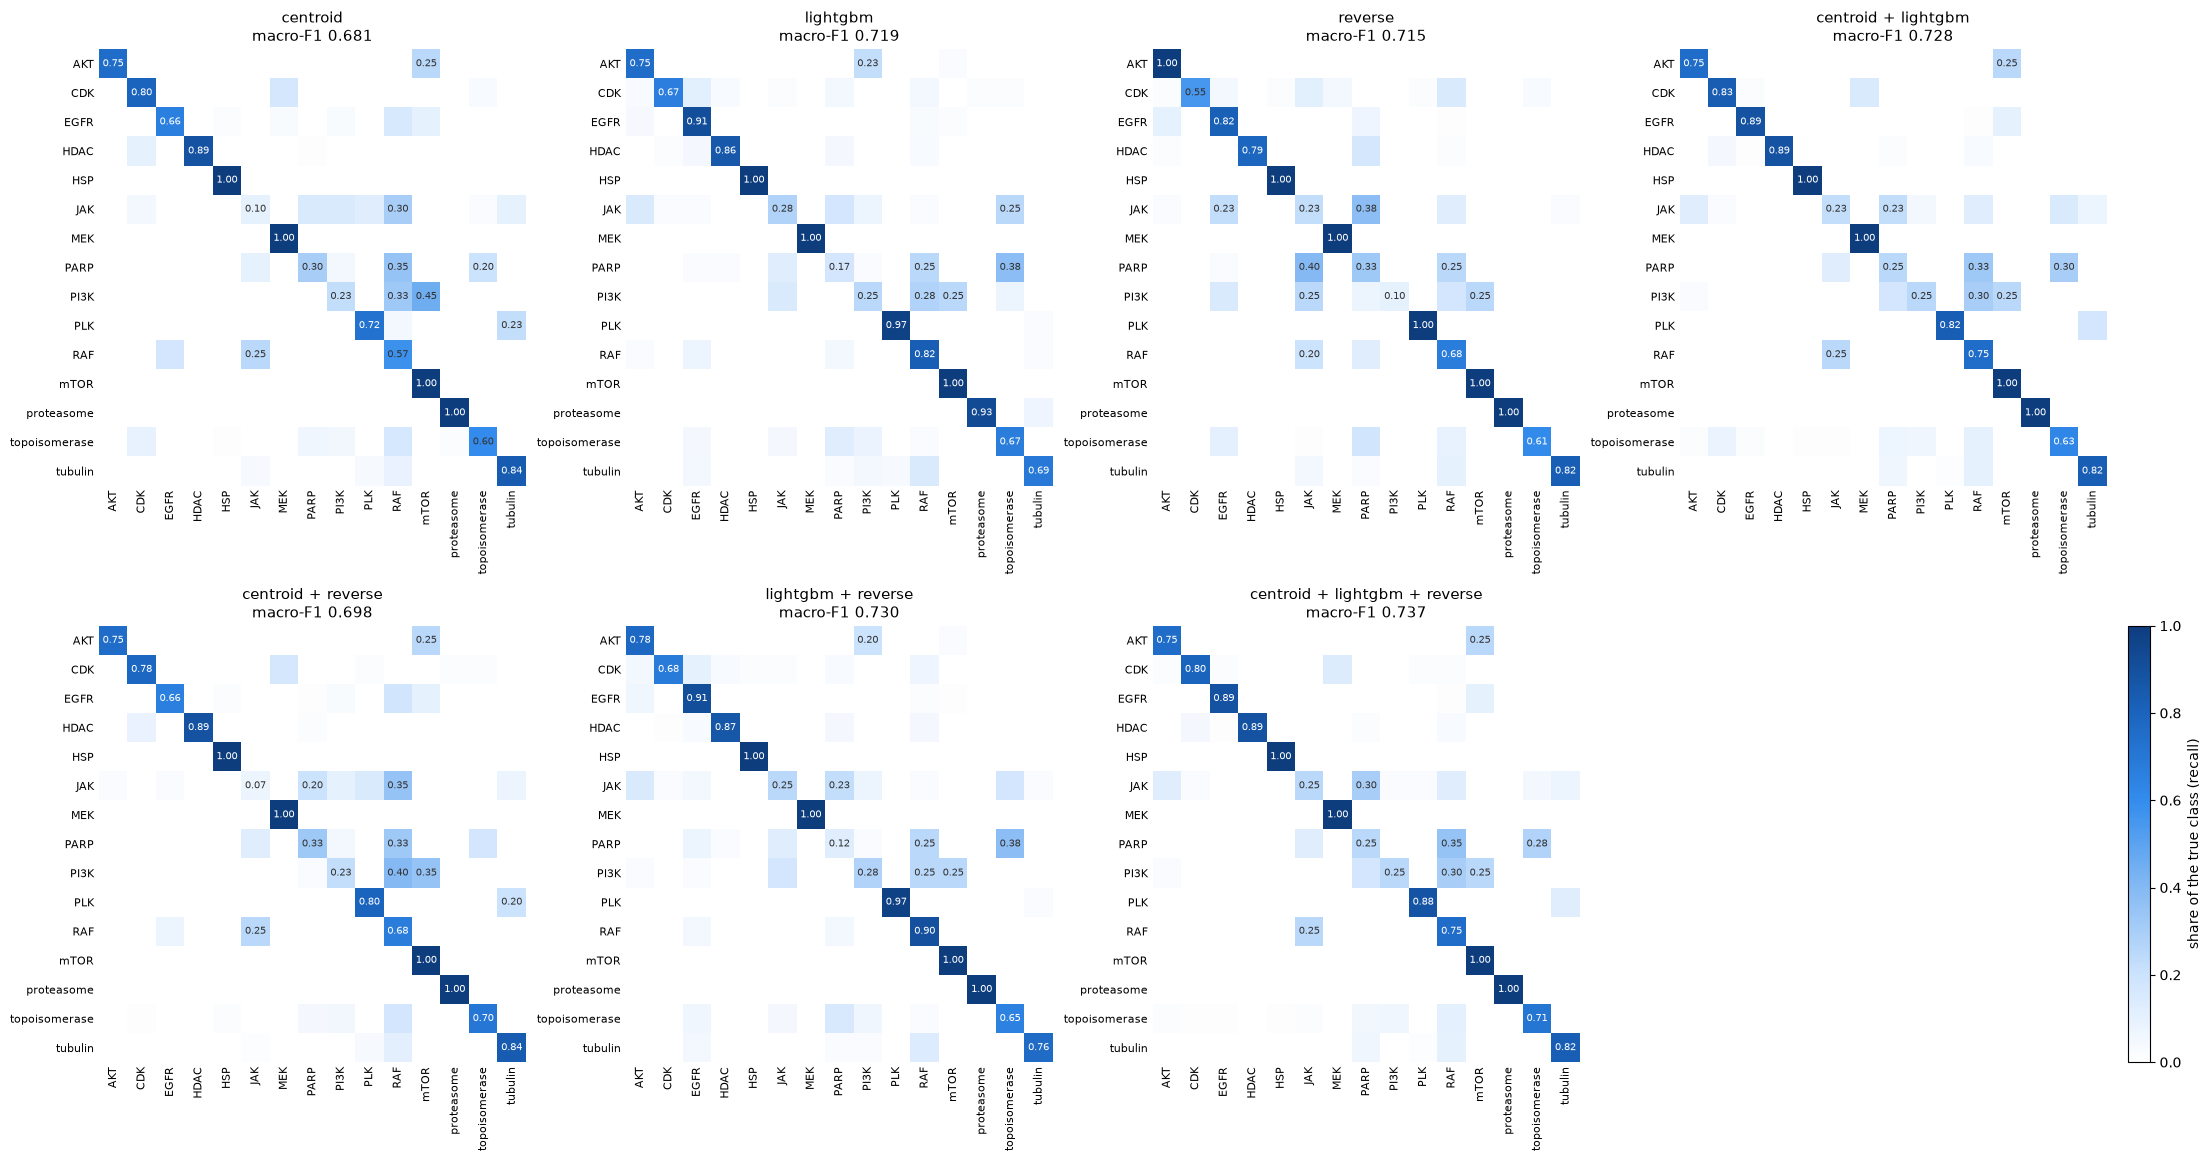

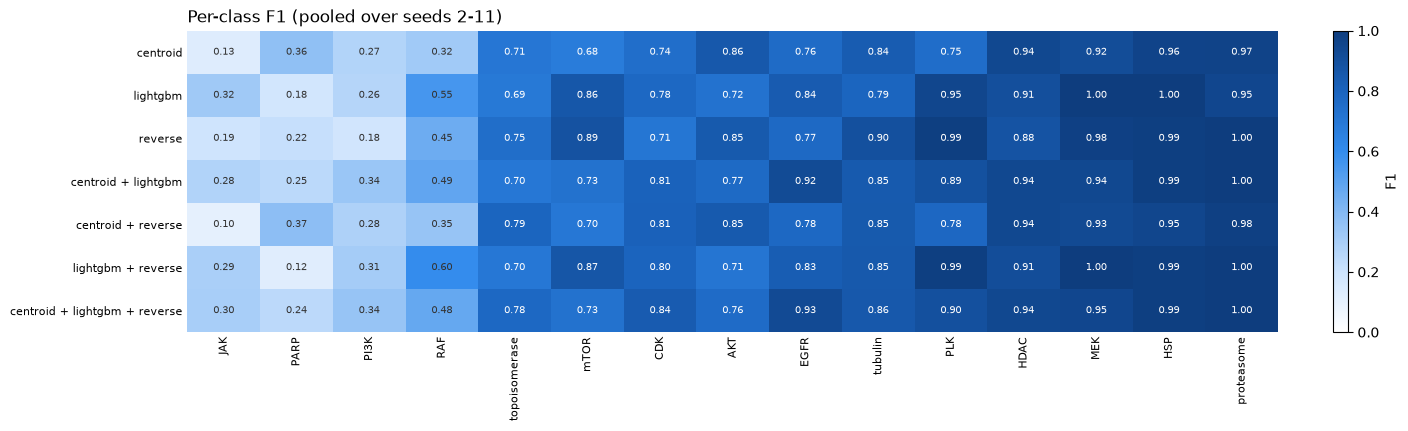

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix
SEQ = LinearSegmentedColormap.from_list("seq", ["#ffffff", "#cce3fd", "#84b9f3", "#338ced", "#1b64be", "#0e3d7e"])
DIV = LinearSegmentedColormap.from_list("div", ["#1b64be", "#84b9f3", "#efefef", "#f5a3a3", "#c62f30"])
short = [c.replace(" polymerization", "").replace(" inhibitor", "") for c in CLASSES]
name = lambda a: " + ".join(a)
pooled = lambda a: (np.tile(yi, len(SEEDS)), PRED[a][sel].ravel())

def heat(ax, M, xl, yl, cmap, vmin, vmax, show=lambda i, j: True, fmt="{:.2f}"):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i, j in np.ndindex(M.shape):
        if show(i, j): ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=7,
                               color="white" if abs(M[i, j]) > 0.6 * vmax else "#333")
    ax.set_xticks(range(len(xl)), xl, rotation=90, fontsize=8); ax.set_yticks(range(len(yl)), yl, fontsize=8)
    ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
    return im

fig, axs = plt.subplots(2, 4, figsize=(22, 11.5), constrained_layout=True)
for ax, a in zip(axs.flat, BLENDS):
    M = confusion_matrix(*pooled(a), labels=range(K), normalize="true")
    im = heat(ax, M, short, short, SEQ, 0, 1, lambda i, j: i == j or M[i, j] >= 0.2)
    ax.set_title(f"{name(a)}\nmacro-F1 {NS[a][sel].mean():.3f}", fontsize=11)
axs.flat[-1].axis("off"); fig.colorbar(im, ax=axs.flat[-1], fraction=0.5, label="share of the true class (recall)")
plt.show()

F1 = pd.DataFrame({name(a): f1_score(*pooled(a), labels=range(K), average=None) for a in BLENDS}, index=short).T
F1 = F1[F1.mean().sort_values().index]
fig, ax = plt.subplots(figsize=(14, 4.2), constrained_layout=True)
fig.colorbar(heat(ax, F1.values, F1.columns, F1.index, SEQ, 0, 1), ax=ax, label="F1")
ax.set_title("Per-class F1 (pooled over seeds 2-11)", loc="left"); plt.show()

## What each model learned
All three models are refit on all 86 training compounds. Every panel has the classes as rows, in the same order.
- **centroid**: each class centroid on the calibrated compound profiles. Shown for the 2 most class-specific genes per class (centroid minus the mean of all centroids).
- **lightgbm**: mean SHAP contribution of each gene to the class's own probability, averaged over that class's signatures. Shown for the top 2 genes per class.
- **reverse**: how strong each class's dose-response template is at each dose (RMS over genes, after the graph high-pass filter). It shows which classes respond at low dose and which only at the top doses.

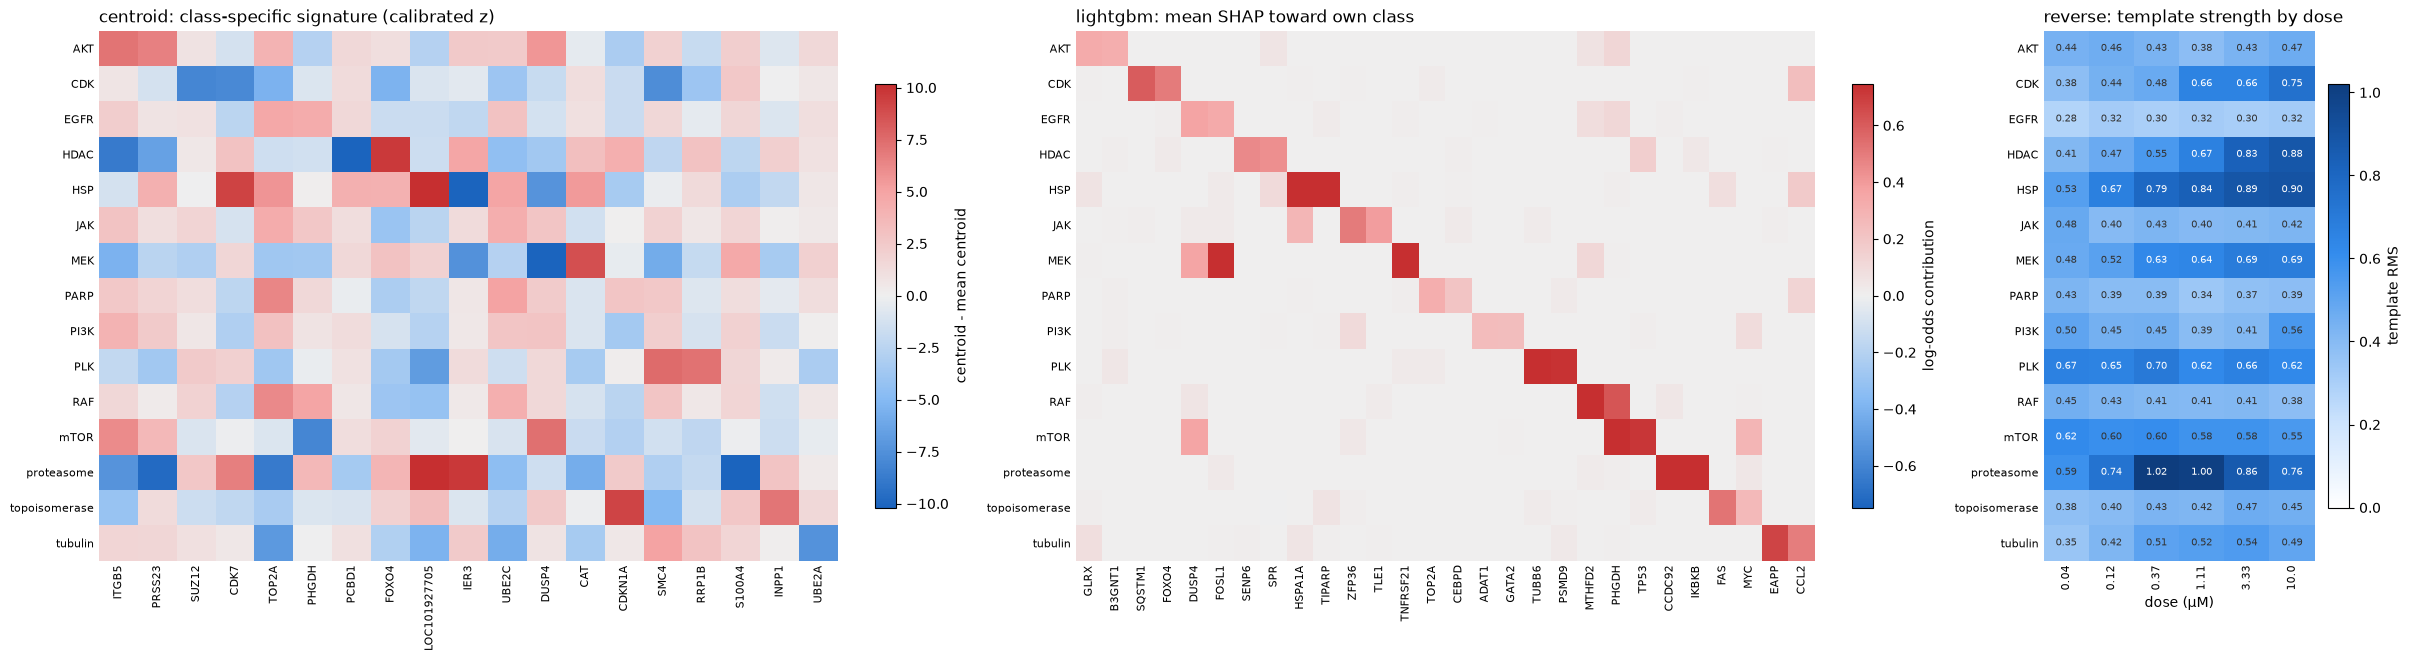

In [8]:
sym = pd.read_csv(f"{DATA}/results/probe2symbol.csv", index_col=0).symbol.reindex(GENES)
sym = sym.fillna(pd.Series(GENES, index=GENES)).values
top = lambda S, k=2: list(dict.fromkeys(j for c in range(K) for j in np.argsort(-np.abs(S[c]))[:k]))
tr = np.arange(n)

cen = np.stack([Z[tr][yi == c].mean(0) for c in range(K)]); cen_spec = cen - cen.mean(0)
rows = np.isin(sc, tr)
m = lgb.LGBMClassifier(**LGB).fit(Zs[rows], yi[sc[rows]])
shap = m.predict(Zs[rows], pred_contrib=True).reshape(rows.sum(), K, -1)[:, :, :-1]   # signatures x classes x genes
lab = yi[sc[rows]]; S_gbm = np.stack([shap[lab == c, c].mean(0) for c in range(K)])
Fa = A[tr].reshape(n, -1); Ft = ((Fa - Fa.mean(0)) / (Fa.std(0) + 1e-6)).reshape(n, *A.shape[1:])
tmpl = np.sqrt((np.stack([Ft[yi == c].mean(0) for c in range(K)]) ** 2).mean(1))   # classes x doses

fig, axs = plt.subplots(1, 3, figsize=(24, 6.5), gridspec_kw={"width_ratios": [3, 3, 1.1]}, constrained_layout=True)
for ax, S, t, lbl in [(axs[0], cen_spec, "centroid: class-specific signature (calibrated z)", "centroid - mean centroid"),
                      (axs[1], S_gbm, "lightgbm: mean SHAP toward own class", "log-odds contribution")]:
    g = top(S); v = np.percentile(np.abs(S[:, g]), 98)
    fig.colorbar(heat(ax, S[:, g], sym[g], short, DIV, -v, v, lambda i, j: False), ax=ax, label=lbl, shrink=0.8)
    ax.set_title(t, loc="left")
fig.colorbar(heat(axs[2], tmpl, [str(d) for d in DOSES], short, SEQ, 0, tmpl.max()), ax=axs[2], label="template RMS", shrink=0.8)
axs[2].set_xlabel("dose (µM)"); axs[2].set_title("reverse: template strength by dose", loc="left")
plt.show()

## Final model and submission
The blend with the best prior-corrected score on seeds 2-11 wins. Its alpha is set on the pooled out-of-fold predictions of those seeds, then it is refit on all 86 compounds.

In [9]:
best = max(BLENDS, key=lambda a: NS[a][sel].mean())
ALPHA = max(ALPHAS, key=lambda a: np.mean([f1(slice(None), blend(RUNS[s][1], best), a) for s in SEEDS]))
tr, q = np.arange(n), np.arange(n, len(allc))
P = blend({a: ARMS[a](tr, q) for a in best}, best) / prior ** ALPHA; P /= P.sum(1, keepdims=True)

out = pd.DataFrame(P, columns=CLASSES); out.insert(0, "compound", test_comps)
out.to_csv(f"{DATA}/submission/submission_best.csv", index=False)
assert list(out.columns) == ["compound"] + CLASSES and np.allclose(out[CLASSES].sum(1), 1)
v2 = pd.read_csv(f"{DATA}/submission/submission_final_v2.csv").set_index("compound").loc[test_comps, CLASSES]
print(f"model: {' + '.join(best)}, alpha={ALPHA} | wrote submission/submission_best.csv ({len(out)} rows)")
print(f"top call agrees with submission_final_v2 on {(v2.values.argmax(1) == P.argmax(1)).sum()}/{len(P)} test compounds")

model: centroid + lightgbm + reverse, alpha=0.5 | wrote submission/submission_best.csv (29 rows)
top call agrees with submission_final_v2 on 28/29 test compounds
